# Hand pose from the egocentric cameras
This notebook builds left and right hand tracks from cam_high and runs diagnostic hand detections on the wrist cameras.

## Setup
Imports, flags and project paths.

In [14]:
import json, time, zipfile, textwrap, urllib.request
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import av
import cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
from tqdm import tqdm

# flags
SMOKE_TEST = False
CAMERAS = ["cam_high", "cam_left_wrist", "cam_right_wrist"]
CONF_CUTOFF = 0.5
MIN_JOINTS = 15
COVERAGE_FLOOR_PCT = 30

# other settings
SMOKE_FRAMES = 600
BENCH_FRAMES = 300
CROP_FRAC = 0.6
DEDUPE_FRAC = 0.05
DET_CONF = 0.3
THUMB_W = 320
N_OVERLAY = 12
SEED = 0
MODEL_URL = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"

DEVICE = {"cam_high": "head", "cam_left_wrist": "left", "cam_right_wrist": "right"}
HANDS = ["left", "right"]
LIMIT = SMOKE_FRAMES if SMOKE_TEST else None

# filled in by later steps
STRATEGY = None
SWAP_LABELS = None
AGREEMENT_PCT = float("nan")
bench_table = None
coverage = None

def stop(msg):
    print("STOP:", msg)
    raise RuntimeError(msg)

def fail(step, err):
    print(f"problem in {step}: {type(err).__name__}: {err}")

print("mediapipe", mp.__version__)
print("smoke test:", SMOKE_TEST)

mediapipe 1.1.1
smoke test: False


In [15]:
ROOT = Path.cwd().parent
CFG_PATH = ROOT / "configs" / "config.yaml"
if not CFG_PATH.exists():
    stop(f"configs\\config.yaml not found in {ROOT}. open this notebook from <PROJECT_ROOT>\\notebooks")

with open(CFG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
print("project root:", ROOT)
print("config keys:", list(cfg.keys()) if isinstance(cfg, dict) else type(cfg).__name__)

REPORTS = ROOT / "reports"
POSE_DIR = ROOT / "interim" / "pose"
MODEL_DIR = ROOT / "configs" / "models"
for d in (REPORTS, POSE_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

project root: c:\workstation\3RD YEAR\ego_pipeline
config keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']


In [16]:
# hand layout, created once if it is not there yet
LAYOUT_PATH = ROOT / "configs" / "hand_layout.yaml"
if not LAYOUT_PATH.exists():
    names = ["wrist"]
    mapping = {"wrist": 0}
    for k, finger in enumerate(["thumb", "index", "middle", "ring", "little"]):
        if finger == "thumb":
            parts = ["metacarpal", "proximal", "distal", "tip"]
            ids = [1, 2, 3, 4]
        else:
            parts = ["metacarpal", "proximal", "intermediate", "distal", "tip"]
            base = 5 + 4 * (k - 1)
            ids = [None, base, base + 1, base + 2, base + 3]
        for part, i in zip(parts, ids):
            names.append(f"{finger}_{part}")
            if i is not None:
                mapping[f"{finger}_{part}"] = i
    new_layout = {
        "provisional": True,
        "note": "provisional layout, replace when the client layout is known",
        "joints": names,
        "mediapipe_mapping": mapping,
    }
    with open(LAYOUT_PATH, "w", encoding="utf-8") as f:
        f.write("# provisional layout, replace when the client layout is known\n")
        yaml.safe_dump(new_layout, f, sort_keys=False)
    print("created", LAYOUT_PATH.name)

with open(LAYOUT_PATH, "r", encoding="utf-8") as f:
    layout = yaml.safe_load(f)
joints = list(layout["joints"])
joint_map = layout["mediapipe_mapping"]
NJ = len(joints)
joint_to_mp = np.array([joint_map.get(j, -1) for j in joints])
missing_joints = joint_to_mp < 0

print("provisional:", layout.get("provisional"), "| joints:", NJ)
print(textwrap.fill(", ".join(joints), 90))
print("structurally missing:", [j for j, m in zip(joints, missing_joints) if m])
if NJ != 25:
    print("warning: the layout has", NJ, "joints, expected 25")

provisional: True | joints: 25
wrist, thumb_metacarpal, thumb_proximal, thumb_distal, thumb_tip, index_metacarpal,
index_proximal, index_intermediate, index_distal, index_tip, middle_metacarpal,
middle_proximal, middle_intermediate, middle_distal, middle_tip, ring_metacarpal,
ring_proximal, ring_intermediate, ring_distal, ring_tip, little_metacarpal,
little_proximal, little_intermediate, little_distal, little_tip
structurally missing: ['index_metacarpal', 'middle_metacarpal', 'ring_metacarpal', 'little_metacarpal']


In [17]:
# episodes and frame counts
s06_path = REPORTS / "06_summary.json"
if not s06_path.exists():
    stop(f"{s06_path} not found")
with open(s06_path, "r", encoding="utf-8") as f:
    s06 = json.load(f)
ids = [i if isinstance(i, str) else str(i.get("episode_id")) for i in s06["episode_ids"]]

def video_path(ep, cam):
    return ROOT / "episodes" / ep / "video" / f"{cam}.h264"

def load_frames(ep, dev):
    z = np.load(ROOT / "episodes" / ep / f"frames_{dev}.npz", allow_pickle=True)
    return {k: z[k] for k in z.files}

def ts_key(d):
    # guess which array holds the per frame timestamps
    keys = [k for k in d if d[k].ndim >= 1 and d[k].shape[0] > 1]
    for k in keys:
        if k.lower() in ("timestamp", "timestamps", "ts", "t"):
            return k
    for k in keys:
        if "time" in k.lower() or "stamp" in k.lower():
            return k
    return keys[0]

n_ts, ts_head, eps = {}, {}, []
for ep in ids:
    try:
        for dev in ("head", "left", "right"):
            d = load_frames(ep, dev)
            k = ts_key(d)
            n_ts[(ep, dev)] = int(d[k].shape[0])
            if dev == "head":
                ts_head[ep] = d[k]
            if not eps:
                print(f"{ep} {dev}: keys {list(d.keys())} -> using {k}")
        for cam in CAMERAS:
            if not video_path(ep, cam).exists():
                raise FileNotFoundError(f"{cam}.h264")
        eps.append(ep)
    except Exception as e:
        print("skipping", ep, "-", type(e).__name__, e)

print("episodes:", eps)
print(pd.DataFrame([{"episode_id": e, "head": n_ts[(e, "head")], "left": n_ts[(e, "left")], "right": n_ts[(e, "right")]} for e in eps]).to_string(index=False))

vendorX_2026-10-11_op01_000001 head: keys ['ts_session_us', 'flags', 'source_clip', 'local_i', 'global_n', 'acc', 'gyro', 'source_clips'] -> using ts_session_us
vendorX_2026-10-11_op01_000001 left: keys ['ts_session_us', 'flags', 'source_clip', 'local_i', 'global_n', 'acc', 'gyro', 'source_clips'] -> using ts_session_us
vendorX_2026-10-11_op01_000001 right: keys ['ts_session_us', 'flags', 'source_clip', 'local_i', 'global_n', 'acc', 'gyro', 'source_clips'] -> using ts_session_us
episodes: ['vendorX_2026-10-11_op01_000001', 'vendorX_2026-10-11_op01_000002', 'vendorX_2026-10-11_op01_000003', 'vendorX_2026-10-11_op01_000004']
                    episode_id  head  left  right
vendorX_2026-10-11_op01_000001 21240 21239  21239
vendorX_2026-10-11_op01_000002  9390  9390   9390
vendorX_2026-10-11_op01_000003 10410 10410  10409
vendorX_2026-10-11_op01_000004 18000 17999  17999


In [18]:
# model file
def find_model():
    own = MODEL_DIR / "hand_landmarker.task"
    if own.exists():
        return own
    found = list(Path(mp.__file__).parent.rglob("hand_landmarker.task"))
    if found:
        return found[0]
    print("downloading hand_landmarker.task")
    tmp = own.with_suffix(".part")
    try:
        urllib.request.urlretrieve(MODEL_URL, str(tmp))
        tmp.replace(own)
    except Exception as e:
        stop(f"could not download the hand landmark model ({e}). get it from {MODEL_URL} and put it in {MODEL_DIR}")
    return own

MODEL_PATH = find_model()
MODEL_BYTES = MODEL_PATH.read_bytes()
print("model:", MODEL_PATH, f"({len(MODEL_BYTES) / 1e6:.1f} MB)")

def make_detector():
    opts = mp_vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_buffer=MODEL_BYTES),
        running_mode=mp_vision.RunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=DET_CONF,
        min_hand_presence_confidence=DET_CONF,
        min_tracking_confidence=DET_CONF,
    )
    return mp_vision.HandLandmarker.create_from_options(opts)

def run_detector(det, rgb):
    # one detector call, landmarks in the coordinates of the given image
    img = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
    res = det.detect(img)
    out = []
    for i, pts in enumerate(res.hand_landmarks):
        lm = np.array([[p.x, p.y, p.z] for p in pts], dtype=np.float32)
        if res.hand_world_landmarks and i < len(res.hand_world_landmarks):
            wl = np.array([[p.x, p.y, p.z] for p in res.hand_world_landmarks[i]], dtype=np.float32)
        else:
            wl = np.full((21, 3), np.nan, dtype=np.float32)
        cat = res.handedness[i][0]
        # landmark presence is often not filled by the tasks api, keep it only when it is
        pres = [p.presence for p in pts]
        if any(v is None for v in pres) or float(np.mean(pres)) <= 0:
            pr = float("nan")
        else:
            pr = float(np.mean(pres))
        out.append({"label": cat.category_name, "score": float(cat.score), "presence": pr, "lm": lm, "world": wl})
    return out

def dedupe(dets, w, h):
    # drop detections whose wrists are closer than DEDUPE_FRAC of the width, keep the higher score
    keep = []
    for d in sorted(dets, key=lambda d: -d["score"]):
        far = True
        for k in keep:
            dx = (d["lm"][0, 0] - k["lm"][0, 0]) * w
            dy = (d["lm"][0, 1] - k["lm"][0, 1]) * h
            if np.hypot(dx, dy) < DEDUPE_FRAC * w:
                far = False
                break
        if far:
            keep.append(d)
    return keep

def detect_full(det, rgb):
    return run_detector(det, rgb)

def detect_crops(det, rgb):
    h, w = rgb.shape[:2]
    cw = int(round(CROP_FRAC * w))
    found = []
    for x0 in (0, w - cw):
        for d in run_detector(det, rgb[:, x0:x0 + cw]):
            d["lm"][:, 0] = (d["lm"][:, 0] * cw + x0) / w
            found.append(d)
    return dedupe(found, w, h)

def open_video(path):
    c = av.open(str(path), format="h264", options={"framerate": "30"})
    c.streams.video[0].thread_type = "AUTO"
    return c

def read_frames(path, limit=None):
    with open_video(path) as c:
        for i, fr in enumerate(c.decode(c.streams.video[0])):
            yield i, fr.to_ndarray(format="rgb24")
            if limit is not None and i + 1 >= limit:
                break

def read_selected(path, wanted):
    # decode in order, convert only the wanted frames
    wanted = set(int(i) for i in wanted)
    last = max(wanted)
    with open_video(path) as c:
        for i, fr in enumerate(c.decode(c.streams.video[0])):
            if i in wanted:
                yield i, fr.to_ndarray(format="rgb24")
            if i >= last:
                break

# quick test on one frame of cam_high
first_frame = None
try:
    for i, rgb in read_frames(video_path(eps[0], "cam_high"), limit=1):
        first_frame = rgb
    print("frame size:", first_frame.shape[1], "x", first_frame.shape[0])
    with make_detector() as det:
        found = run_detector(det, first_frame)
    print("hands found in frame 0 of cam_high:", len(found))
except Exception as e:
    fail("detector test", e)

model: c:\workstation\3RD YEAR\ego_pipeline\configs\models\hand_landmarker.task (7.8 MB)
frame size: 1920 x 1080
hands found in frame 0 of cam_high: 2


## Strategy test
Compares the full frame with two overlapping crops on 300 evenly spaced frames of cam_high from the first episode.

In [19]:
bench_dets = {"full": {}, "crops": {}}
try:
    ep0 = eps[0]
    n_head = n_ts[(ep0, "head")]
    idx = np.unique(np.linspace(0, n_head - 1, BENCH_FRAMES).astype(int))
    secs = {"full": 0.0, "crops": 0.0}
    strategies = (("full", detect_full), ("crops", detect_crops))
    with make_detector() as det:
        if first_frame is not None:
            for name, fn in strategies:
                fn(det, first_frame)  # warm up
        for i, rgb in tqdm(read_selected(video_path(ep0, "cam_high"), idx), total=len(idx), desc="benchmark", unit="fr"):
            for name, fn in strategies:
                t0 = time.perf_counter()
                found = fn(det, rgb)
                secs[name] += time.perf_counter() - t0
                bench_dets[name][i] = found

    rows = []
    for name, _ in strategies:
        cnt = np.array([len(v) for v in bench_dets[name].values()])
        rows.append({
            "strategy": name,
            "frames": len(cnt),
            "pct_one_or_more": 100 * float(np.mean(cnt >= 1)),
            "pct_two": 100 * float(np.mean(cnt >= 2)),
            "fps": len(cnt) / secs[name],
        })
    bench_table = pd.DataFrame(rows)
    best = bench_table.sort_values(["pct_two", "fps"], ascending=[False, False]).iloc[0]
    STRATEGY = str(best["strategy"])
    bench_table["chosen"] = bench_table["strategy"] == STRATEGY
    bench_table.to_csv(REPORTS / "09_detection_benchmark.csv", index=False)
    print(bench_table.round(2).to_string(index=False))
    print("chosen strategy for cam_high:", STRATEGY)
except Exception as e:
    fail("strategy test", e)

benchmark: 100%|██████████| 300/300 [02:54<00:00,  1.72fr/s]


strategy  frames  pct_one_or_more  pct_two   fps  chosen
    full     300            100.0    94.67 10.39    True
   crops     300            100.0    92.33  6.25   False
chosen strategy for cam_high: full


## Handedness
Checks whether the Left and Right labels agree with the side of the image where the wrist is, using the same 300 frames.

In [20]:
try:
    if STRATEGY is None:
        raise RuntimeError("no strategy chosen, step 2 did not finish")
    cnt = {("Left", "left"): 0, ("Left", "right"): 0, ("Right", "left"): 0, ("Right", "right"): 0}
    for found in bench_dets[STRATEGY].values():
        for d in found:
            side = "left" if d["lm"][0, 0] < 0.5 else "right"
            cnt[(d["label"], side)] += 1
    total = sum(cnt.values())
    if total == 0:
        raise RuntimeError("no hands detected in the 300 frames")
    agree_direct = 100 * (cnt[("Left", "left")] + cnt[("Right", "right")]) / total
    agree_swap = 100 - agree_direct
    SWAP_LABELS = agree_swap > agree_direct
    AGREEMENT_PCT = max(agree_direct, agree_swap)
    mapping_name = "swap" if SWAP_LABELS else "direct"

    hand_rows = [{
        "camera": "cam_high",
        "rule": "label compared with wrist side",
        "n_detections": total,
        "label_left_wrist_left_half": cnt[("Left", "left")],
        "label_left_wrist_right_half": cnt[("Left", "right")],
        "label_right_wrist_left_half": cnt[("Right", "left")],
        "label_right_wrist_right_half": cnt[("Right", "right")],
        "agree_direct_pct": agree_direct,
        "agree_swap_pct": agree_swap,
        "mapping": mapping_name,
        "agreement_pct": AGREEMENT_PCT,
    }]
    for cam, hand in (("cam_left_wrist", "left"), ("cam_right_wrist", "right")):
        hand_rows.append({"camera": cam, "rule": f"every detection is the {hand} hand", "mapping": "by camera"})
    pd.DataFrame(hand_rows).to_csv(REPORTS / "09_handedness_check.csv", index=False)

    print("label x side counts:", {f"{a}/{b}": v for (a, b), v in cnt.items()})
    print(f"agreement direct {agree_direct:.1f}%, swapped {agree_swap:.1f}%")
    print("mapping for cam_high:", mapping_name, f"({AGREEMENT_PCT:.1f}% agreement)")
except Exception as e:
    fail("handedness", e)

label x side counts: {'Left/left': 3, 'Left/right': 272, 'Right/left': 290, 'Right/right': 19}
agreement direct 3.8%, swapped 96.2%
mapping for cam_high: swap (96.2% agreement)


## Detection
Runs the detector on every stream and caches the result in interim\pose. Streams that are already cached are skipped.

In [21]:
def cache_path(ep, cam):
    return POSE_DIR / f"{ep}_{cam}.npz"

def stream_strategy(cam):
    return STRATEGY if cam == "cam_high" else "full"

def load_dets(ep, cam):
    z = np.load(cache_path(ep, cam), allow_pickle=False)
    return {k: z[k] for k in z.files}

def cache_ok(ep, cam):
    if not cache_path(ep, cam).exists():
        return False
    try:
        z = load_dets(ep, cam)
        return int(z["limit"]) == (LIMIT or 0) and str(z["strategy"]) == stream_strategy(cam)
    except Exception:
        return False

def detect_stream(ep, cam):
    strat = stream_strategy(cam)
    fn = detect_crops if strat == "crops" else detect_full
    total = n_ts[(ep, DEVICE[cam])]
    if LIMIT:
        total = min(total, LIMIT)
    frame_ids, labels, scores, pres, lms, wls = [], [], [], [], [], []
    n = 0
    t0 = time.perf_counter()
    with make_detector() as det:
        for i, rgb in tqdm(read_frames(video_path(ep, cam), LIMIT), total=total, desc=f"{ep} {cam}", unit="fr"):
            for d in fn(det, rgb):
                frame_ids.append(i)
                labels.append(0 if d["label"] == "Left" else 1)
                scores.append(d["score"])
                pres.append(d["presence"])
                lms.append(d["lm"])
                wls.append(d["world"])
            n = i + 1
    secs = time.perf_counter() - t0
    fps = n / secs if secs > 0 else 0.0
    tmp = cache_path(ep, cam).with_name(f"{ep}_{cam}.part.npz")
    np.savez(
        tmp,
        det_frame=np.array(frame_ids, dtype=np.int32),
        det_label=np.array(labels, dtype=np.int8),
        det_score=np.array(scores, dtype=np.float32),
        det_presence=np.array(pres, dtype=np.float32),
        det_lm=np.array(lms, dtype=np.float32).reshape(-1, 21, 3),
        det_world=np.array(wls, dtype=np.float32).reshape(-1, 21, 3),
        n_frames=np.array(n),
        limit=np.array(LIMIT or 0),
        strategy=np.array(strat),
        secs=np.array(secs),
        fps=np.array(fps),
    )
    tmp.replace(cache_path(ep, cam))
    return n, secs, fps

if STRATEGY is None:
    STRATEGY = "full"
    print("no benchmark result, using the full frame for cam_high")

stream_stats = {}
for ep in eps:
    for cam in CAMERAS:
        try:
            if cache_ok(ep, cam):
                z = load_dets(ep, cam)
                stream_stats[(ep, cam)] = {"frames": int(z["n_frames"]), "secs": float(z["secs"]), "fps": float(z["fps"])}
                print(f"{ep} {cam}: cached, skipped")
            else:
                n, secs, fps = detect_stream(ep, cam)
                stream_stats[(ep, cam)] = {"frames": n, "secs": secs, "fps": fps}
                print(f"{ep} {cam}: {n} frames, {fps:.1f} fps")
        except Exception as e:
            fail(f"detection {ep} {cam}", e)

if SMOKE_TEST and stream_stats:
    est = sum(n_ts[(ep, DEVICE[cam])] / st["fps"] for (ep, cam), st in stream_stats.items() if st["fps"] > 0)
    print(f"smoke test only, the full run would take about {est / 60:.0f} min")

vendorX_2026-10-11_op01_000001 cam_high: 100%|██████████| 21240/21240 [20:42<00:00, 17.09fr/s]


vendorX_2026-10-11_op01_000001 cam_high: 21240 frames, 17.1 fps


vendorX_2026-10-11_op01_000001 cam_left_wrist: 100%|██████████| 21239/21239 [13:37<00:00, 25.97fr/s]


vendorX_2026-10-11_op01_000001 cam_left_wrist: 21239 frames, 26.0 fps


vendorX_2026-10-11_op01_000001 cam_right_wrist: 100%|██████████| 21239/21239 [11:19<00:00, 31.27fr/s]


...

vendorX_2026-10-11_op01_000004 cam_high: 18000 frames, 16.2 fps


vendorX_2026-10-11_op01_000004 cam_left_wrist: 100%|██████████| 17999/17999 [12:15<00:00, 24.48fr/s]


vendorX_2026-10-11_op01_000004 cam_left_wrist: 17999 frames, 24.5 fps


vendorX_2026-10-11_op01_000004 cam_right_wrist: 100%|██████████| 17999/17999 [13:31<00:00, 22.17fr/s]


vendorX_2026-10-11_op01_000004 cam_right_wrist: 17999 frames, 22.2 fps


## Hand tracks
Builds the left and right hand arrays from the cam_high detections, mapped to the 25 joint layout, and saves them per episode.

In [22]:
if SWAP_LABELS is None:
    SWAP_LABELS = False
    print("no handedness result, using the labels as they are")

def dets_by_frame(z):
    out = {}
    for k in range(len(z["det_frame"])):
        out.setdefault(int(z["det_frame"][k]), []).append({
            "label": "Left" if z["det_label"][k] == 0 else "Right",
            "score": float(z["det_score"][k]),
            "presence": float(z["det_presence"][k]),
            "lm": z["det_lm"][k],
        })
    return out

def hand_of(label):
    if SWAP_LABELS:
        return "right" if label == "Left" else "left"
    return "left" if label == "Left" else "right"

def assign(dets):
    # best scoring detection for each hand
    best = {}
    for d in dets:
        h = hand_of(d["label"])
        if h not in best or d["score"] > best[h]["score"]:
            best[h] = d
    return best

def build_tracks(ep):
    z = load_dets(ep, "cam_high")
    n = int(z["n_frames"])
    out = {h: {
        "position": np.full((n, NJ, 3), np.nan, dtype=np.float32),
        "confidence": np.zeros((n, NJ), dtype=np.float32),
        "detected": np.zeros(n, dtype=bool),
        "out_of_frame": np.zeros(n, dtype=bool),
    } for h in HANDS}
    has_mp = joint_to_mp >= 0
    for f, dets in dets_by_frame(z).items():
        for h, d in assign(dets).items():
            t = out[h]
            t["detected"][f] = True
            conf = float(np.nanmin([d["score"], d["presence"]]))
            pos = np.full((NJ, 3), np.nan, dtype=np.float32)
            pos[has_mp] = d["lm"][joint_to_mp[has_mp]]
            outside = has_mp & ((pos[:, 0] < 0) | (pos[:, 0] > 1) | (pos[:, 1] < 0) | (pos[:, 1] > 1))
            valid = has_mp & ~outside
            pos[~valid] = np.nan
            t["position"][f] = pos
            t["confidence"][f] = np.where(valid, conf, 0.0)
            t["out_of_frame"][f] = bool(outside.any())
    ts = ts_head[ep][:n]
    for h in HANDS:
        t = out[h]
        np.savez(
            ROOT / "episodes" / ep / f"hand_{h}.npz",
            position=t["position"],
            confidence=t["confidence"],
            detected=t["detected"],
            out_of_frame=t["out_of_frame"],
            frame_index=np.arange(n),
            timestamp=ts,
            joints=np.array(joints),
            position_tag=np.array("hand_2d_normalized"),
        )
    return n, out

for ep in eps:
    try:
        n, out = build_tracks(ep)
        print(f"{ep}: {n} frames, detected left {100 * out['left']['detected'].mean():.1f}%, right {100 * out['right']['detected'].mean():.1f}%")
    except Exception as e:
        fail(f"tracks {ep}", e)

vendorX_2026-10-11_op01_000001: 21240 frames, detected left 98.7%, right 90.2%
vendorX_2026-10-11_op01_000002: 9390 frames, detected left 99.4%, right 89.2%
vendorX_2026-10-11_op01_000003: 10410 frames, detected left 98.8%, right 89.1%
vendorX_2026-10-11_op01_000004: 18000 frames, detected left 99.1%, right 89.5%


## Coverage
Share of frames with a detection, with a tracked hand and out of frame, for each episode and hand, plus the wrist camera detection share.

In [23]:
def load_track(ep, hand):
    z = np.load(ROOT / "episodes" / ep / f"hand_{hand}.npz", allow_pickle=False)
    return {k: z[k] for k in z.files}

def tracked_mask(conf):
    # tracked: at least MIN_JOINTS joints with confidence and their mean confidence at least CONF_CUTOFF
    valid = conf > 0
    nv = valid.sum(axis=1)
    mean_conf = np.where(nv > 0, conf.sum(axis=1) / np.maximum(nv, 1), 0.0)
    return (nv >= MIN_JOINTS) & (mean_conf >= CONF_CUTOFF)

def wrist_share(ep, cam):
    try:
        z = load_dets(ep, cam)
        n = int(z["n_frames"])
        return 100 * len(np.unique(z["det_frame"])) / n if n else float("nan")
    except Exception:
        return float("nan")

rows = []
for ep in eps:
    for h in HANDS:
        try:
            t = load_track(ep, h)
            n = len(t["detected"])
            wcam = "cam_left_wrist" if h == "left" else "cam_right_wrist"
            rows.append({
                "episode_id": ep,
                "hand": h,
                "frames": n,
                "detected_pct": 100 * float(t["detected"].mean()),
                "tracked_pct": 100 * float(tracked_mask(t["confidence"]).mean()),
                "out_of_frame_pct": 100 * float(t["out_of_frame"].mean()),
                "wrist_cam_detected_pct": wrist_share(ep, wcam),
            })
        except Exception as e:
            fail(f"coverage {ep} {h}", e)

try:
    coverage = pd.DataFrame(rows)
    low = coverage.groupby("episode_id")["tracked_pct"].min() < COVERAGE_FLOOR_PCT
    coverage["low_coverage_flag"] = coverage["episode_id"].map(low)
    coverage = coverage[["episode_id", "hand", "frames", "detected_pct", "tracked_pct", "out_of_frame_pct", "low_coverage_flag", "wrist_cam_detected_pct"]]
    coverage.to_csv(REPORTS / "09_coverage.csv", index=False)
    print(coverage.round(1).to_string(index=False))
except Exception as e:
    fail("coverage table", e)

                    episode_id  hand  frames  detected_pct  tracked_pct  out_of_frame_pct  low_coverage_flag  wrist_cam_detected_pct
vendorX_2026-10-11_op01_000001  left   21240          98.7         98.7               0.1              False                    33.9
vendorX_2026-10-11_op01_000001 right   21240          90.2         90.2               0.2              False                    13.1
vendorX_2026-10-11_op01_000002  left    9390          99.4         99.4               1.9              False                    43.2
vendorX_2026-10-11_op01_000002 right    9390          89.2         89.2               0.0              False                    10.9
vendorX_2026-10-11_op01_000003  left   10410          98.8         98.8               0.0              False                    21.8
vendorX_2026-10-11_op01_000003 right   10410          89.1         89.1               0.0              False                    10.6
vendorX_2026-10-11_op01_000004  left   18000          99.1         99

## Overlay sheets
One image per episode with 12 random frames. cam_high has the hands drawn (left blue, right red), the wrist cameras are below each frame.

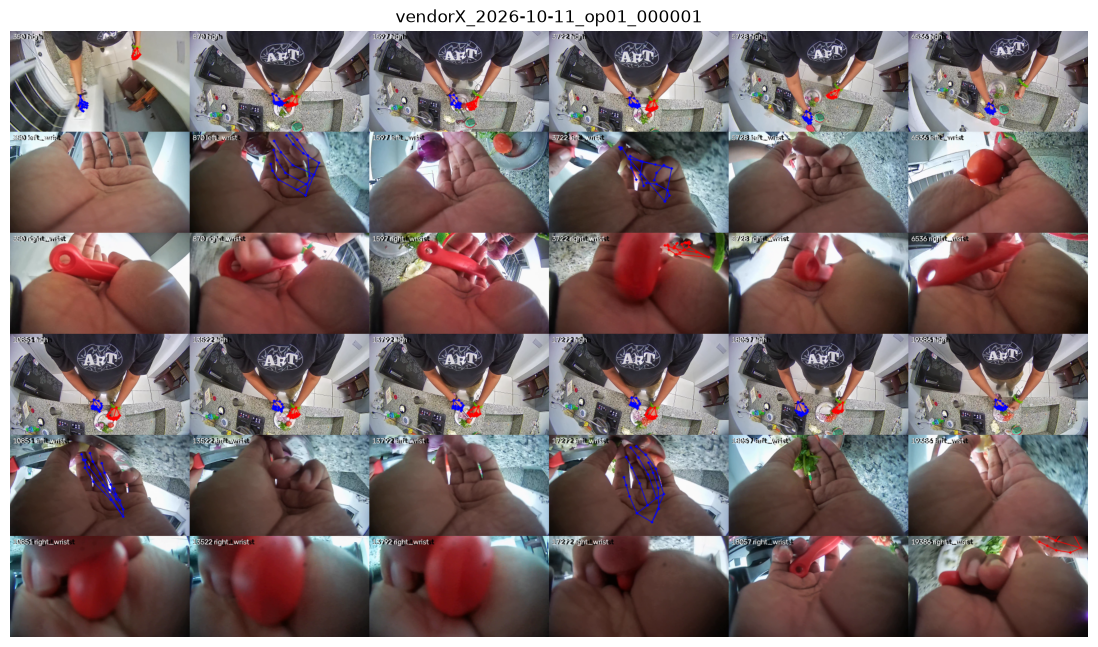

saved 09_overlay_vendorX_2026-10-11_op01_000001.png


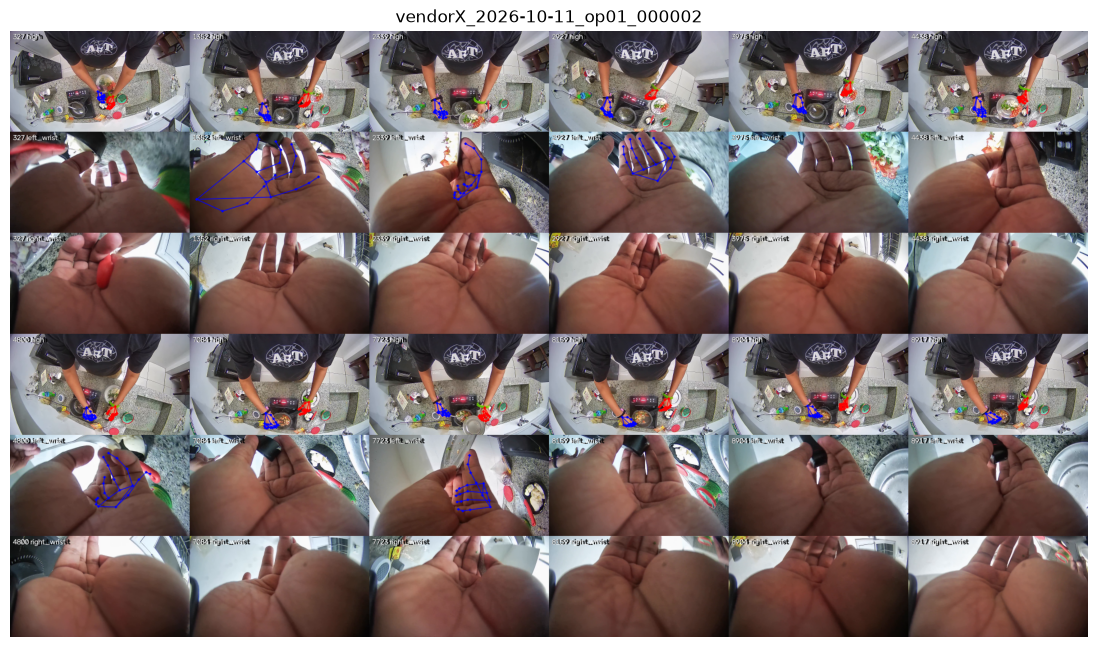

saved 09_overlay_vendorX_2026-10-11_op01_000002.png


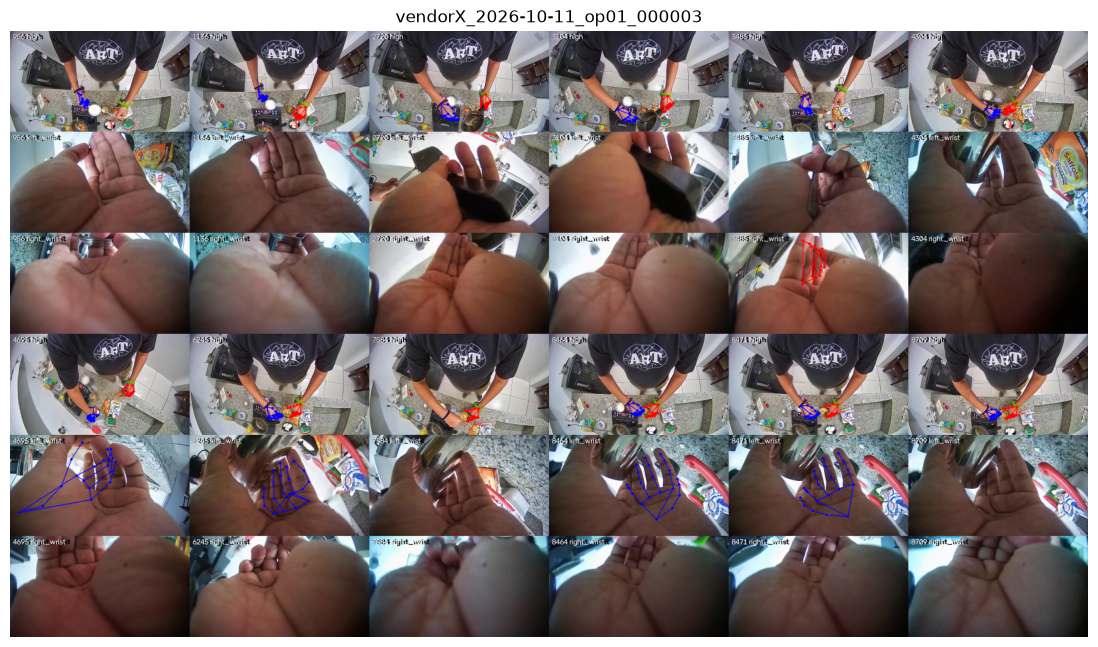

saved 09_overlay_vendorX_2026-10-11_op01_000003.png


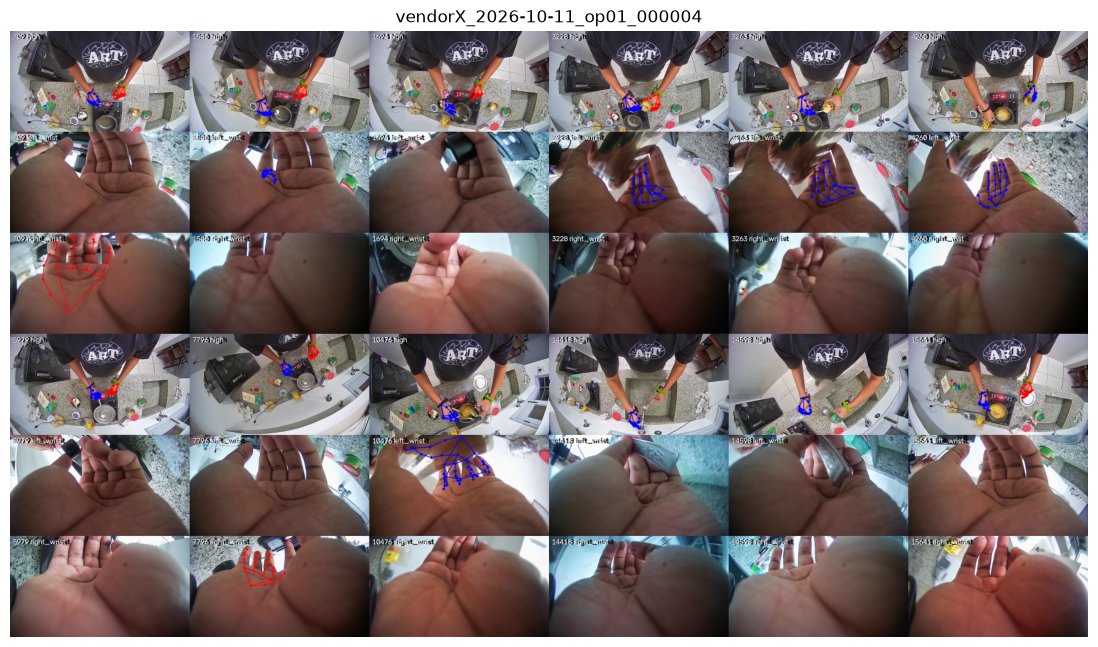

saved 09_overlay_vendorX_2026-10-11_op01_000004.png


In [24]:
BONES = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (9, 10), (10, 11), (11, 12),
         (13, 14), (14, 15), (15, 16), (0, 17), (17, 18), (18, 19), (19, 20), (5, 9), (9, 13), (13, 17)]
COLOR = {"left": (0, 0, 255), "right": (255, 0, 0)}  # rgb
TH = int(round(THUMB_W * first_frame.shape[0] / first_frame.shape[1])) if first_frame is not None else 180

def draw_hand(img, lm, color):
    h, w = img.shape[:2]
    pts = [(int(round(float(x) * w)), int(round(float(y) * h))) for x, y, _ in lm]
    for a, b in BONES:
        cv2.line(img, pts[a], pts[b], color, 1, cv2.LINE_AA)
    for p in pts:
        cv2.circle(img, p, 2, color, -1, cv2.LINE_AA)

def put_label(img, text):
    cv2.putText(img, text, (5, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 3, cv2.LINE_AA)
    cv2.putText(img, text, (5, 15), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)

def grab_thumbs(ep, cam, picks):
    out = {}
    for i, rgb in read_selected(video_path(ep, cam), picks):
        out[i] = cv2.resize(rgb, (THUMB_W, TH), interpolation=cv2.INTER_AREA)
    return out

def make_sheet(ep, picks):
    thumbs, by_frame = {}, {}
    for cam in CAMERAS:
        try:
            thumbs[cam] = grab_thumbs(ep, cam, picks)
            by_frame[cam] = dets_by_frame(load_dets(ep, cam))
        except Exception as e:
            fail(f"overlay {ep} {cam}", e)
            thumbs[cam], by_frame[cam] = {}, {}
    ncol = 6
    blocks = int(np.ceil(len(picks) / ncol))
    nrow = len(CAMERAS)
    sheet = np.full((blocks * nrow * TH, ncol * THUMB_W, 3), 40, dtype=np.uint8)
    for n, f in enumerate(picks):
        b, c = divmod(n, ncol)
        for r, cam in enumerate(CAMERAS):
            img = thumbs[cam].get(int(f))
            img = np.full((TH, THUMB_W, 3), 90, dtype=np.uint8) if img is None else img.copy()
            dets = by_frame[cam].get(int(f), [])
            if cam == "cam_high":
                for h, d in assign(dets).items():
                    draw_hand(img, d["lm"], COLOR[h])
            else:
                for d in dets:
                    draw_hand(img, d["lm"], COLOR["left" if cam == "cam_left_wrist" else "right"])
            put_label(img, f"{int(f)} {cam.replace('cam_', '')}")
            y0 = (b * nrow + r) * TH
            sheet[y0:y0 + TH, c * THUMB_W:(c + 1) * THUMB_W] = img
    return sheet

for k, ep in enumerate(eps):
    try:
        n = int(load_dets(ep, "cam_high")["n_frames"])
        rng = np.random.default_rng(SEED + k)
        picks = np.sort(rng.choice(n, size=min(N_OVERLAY, n), replace=False))
        sheet = make_sheet(ep, picks)
        out_path = REPORTS / f"09_overlay_{ep}.png"
        ok, buf = cv2.imencode(".png", cv2.cvtColor(sheet, cv2.COLOR_RGB2BGR))
        buf.tofile(str(out_path))
        plt.figure(figsize=(14, 14 * sheet.shape[0] / sheet.shape[1]))
        plt.imshow(sheet)
        plt.axis("off")
        plt.title(ep)
        plt.show()
        print("saved", out_path.name)
    except Exception as e:
        fail(f"overlay {ep}", e)

## Hypothesis tests
Checks on the saved arrays and the coverage table. Each row is computed from the files.

In [25]:
tests = []

def add(tid, hyp, measured, result):
    tests.append({"id": tid, "hypothesis": hyp, "measured": measured, "result": result})

tr = {}
for ep in eps:
    for h in HANDS:
        try:
            tr[(ep, h)] = load_track(ep, h)
        except Exception as e:
            fail(f"load track {ep} {h}", e)

def expected_frames(ep, cam):
    e = n_ts[(ep, DEVICE[cam])]
    return min(e, LIMIT) if LIMIT else e

# H1 frame counts
try:
    bad = total = 0
    for ep in eps:
        for cam in CAMERAS:
            total += 1
            if int(load_dets(ep, cam)["n_frames"]) != expected_frames(ep, cam):
                bad += 1
        n_head = int(load_dets(ep, "cam_high")["n_frames"])
        for h in HANDS:
            total += 1
            t = tr[(ep, h)]
            sizes = [t[k].shape[0] for k in ("position", "confidence", "detected", "out_of_frame", "frame_index", "timestamp")]
            if any(s != n_head for s in sizes):
                bad += 1
    add("H1", "every output has as many frames as its video", f"{bad} of {total} outputs differ", "PASS" if bad == 0 else "FLAG")
except Exception as e:
    add("H1", "every output has as many frames as its video", f"error: {e}", "FLAG")

# H2 nan iff confidence 0
try:
    bad = total = 0
    for t in tr.values():
        nan_any = np.isnan(t["position"]).any(axis=-1)
        nan_all = np.isnan(t["position"]).all(axis=-1)
        zero = t["confidence"] == 0
        bad += int(((nan_any != zero) | (nan_all != nan_any)).sum())
        total += nan_any.size
    add("H2", "NaN if and only if confidence 0, every joint", f"{bad} of {total} joint values break the rule", "PASS" if bad == 0 else "FLAG")
except Exception as e:
    add("H2", "NaN if and only if confidence 0, every joint", f"error: {e}", "FLAG")

# H3 structurally missing joints
try:
    bad = total = 0
    for t in tr.values():
        pos = t["position"][:, missing_joints]
        conf = t["confidence"][:, missing_joints]
        bad += int((~np.isnan(pos)).sum() + (conf != 0).sum())
        total += pos.size + conf.size
    add("H3", "the structurally missing joints are NaN with confidence 0 in every frame", f"{bad} of {total} values break the rule", "PASS" if bad == 0 else "FLAG")
except Exception as e:
    add("H3", "the structurally missing joints are NaN with confidence 0 in every frame", f"error: {e}", "FLAG")

# H4 positions inside the image
try:
    bad = total = 0
    for t in tr.values():
        xy = t["position"][..., :2][t["confidence"] > 0]
        bad += int(((xy < 0) | (xy > 1)).sum())
        total += xy.size
    add("H4", "positions of joints with confidence above 0 are inside [0, 1]", f"{bad} of {total} values outside", "PASS" if bad == 0 else "FLAG")
except Exception as e:
    add("H4", "positions of joints with confidence above 0 are inside [0, 1]", f"error: {e}", "FLAG")

# H5 coverage table complete
try:
    want = {(ep, h) for ep in eps for h in HANDS}
    have = set(zip(coverage["episode_id"], coverage["hand"]))
    ok = want == have and bool(coverage["low_coverage_flag"].notna().all())
    add("H5", "coverage and low_coverage_flag exist for every episode and hand", f"{len(have)} of {len(want)} rows present", "PASS" if ok else "FLAG")
except Exception as e:
    add("H5", "coverage and low_coverage_flag exist for every episode and hand", f"error: {e}", "FLAG")

# H6 low coverage flags
try:
    low = coverage[coverage["low_coverage_flag"]]
    if low.empty:
        txt = "no episode flagged"
    else:
        txt = "; ".join(f"{r.episode_id} {r.hand} tracked {r.tracked_pct:.1f}%" for r in low.itertuples())
    add("H6", "low coverage flags (tracked share below the floor)", txt, "INFO")
except Exception as e:
    add("H6", "low coverage flags (tracked share below the floor)", f"error: {e}", "FLAG")

# H7 handedness agreement
try:
    ok = AGREEMENT_PCT >= 90
    add("H7", "handedness mapping agreement at least 90 percent", f"{AGREEMENT_PCT:.1f}%", "PASS" if ok else "FLAG")
except Exception as e:
    add("H7", "handedness mapping agreement at least 90 percent", f"error: {e}", "FLAG")

# H8 speed
try:
    parts = []
    for cam in CAMERAS:
        fr = sum(st["frames"] for (e, c), st in stream_stats.items() if c == cam)
        sc = sum(st["secs"] for (e, c), st in stream_stats.items() if c == cam)
        parts.append(f"{cam} {fr / sc:.1f} fps")
    fr_all = sum(st["frames"] for st in stream_stats.values())
    sc_all = sum(st["secs"] for st in stream_stats.values())
    kind = "smoke test" if SMOKE_TEST else "full run"
    add("H8", "frames per second of the run", f"{kind}: {fr_all / sc_all:.1f} fps overall ({', '.join(parts)})", "INFO")
except Exception as e:
    add("H8", "frames per second of the run", f"error: {e}", "FLAG")

# H9 wrist cameras
try:
    txt = "; ".join(f"{r.episode_id} {r.hand} {r.wrist_cam_detected_pct:.1f}%" for r in coverage.itertuples())
    add("H9", "wrist camera detection shares", txt, "INFO")
except Exception as e:
    add("H9", "wrist camera detection shares", f"error: {e}", "FLAG")

hyp_table = pd.DataFrame(tests)
hyp_table.to_csv(REPORTS / "09_hypothesis_check.csv", index=False)
print(hyp_table.to_string(index=False))

id                                                               hypothesis                                                                                                                                                                                                                                                                                                                                                   measured result
H1                             every output has as many frames as its video                                                                                                                                                                                                                                                                                                                                     0 of 20 outputs differ   PASS
H2                             NaN if and only if confidence 0, every joint                                                                 

## Summary
Writes the summary json and zips the 09_ files from the reports folder.

In [26]:
def records(df):
    if df is None:
        return None
    return json.loads(df.to_json(orient="records"))

try:
    summary = {
        "run_time_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "smoke_test": SMOKE_TEST,
        "mediapipe_version": mp.__version__,
        "position_tag": "hand_2d_normalized",
        "layout_provisional": layout.get("provisional"),
        "strategy_chosen": STRATEGY,
        "handedness_mapping": "swap" if SWAP_LABELS else "direct",
        "handedness_agreement_pct": None if np.isnan(AGREEMENT_PCT) else float(AGREEMENT_PCT),
        "benchmark": records(bench_table),
        "coverage": records(coverage),
        "tests": records(hyp_table),
        "detection_seconds_total": float(sum(st["secs"] for st in stream_stats.values())),
    }
    with open(REPORTS / "09_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    zip_path = REPORTS / "share_09.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(REPORTS.glob("09_*")):
            if p.suffix != ".npz":
                z.write(p, p.name)
        names = z.namelist()

    print("strategy:", STRATEGY, "| handedness mapping:", summary["handedness_mapping"])
    if coverage is not None:
        for r in coverage.itertuples():
            print(f"{r.episode_id} {r.hand}: detected {r.detected_pct:.1f}%, tracked {r.tracked_pct:.1f}%, out of frame {r.out_of_frame_pct:.1f}%")
    res = hyp_table["result"].value_counts().to_dict()
    print("tests:", res)
    print("files in zip:", len(names))
    print("zip:", zip_path)
except Exception as e:
    fail("summary", e)

strategy: full | handedness mapping: swap
vendorX_2026-10-11_op01_000001 left: detected 98.7%, tracked 98.7%, out of frame 0.1%
vendorX_2026-10-11_op01_000001 right: detected 90.2%, tracked 90.2%, out of frame 0.2%
vendorX_2026-10-11_op01_000002 left: detected 99.4%, tracked 99.4%, out of frame 1.9%
vendorX_2026-10-11_op01_000002 right: detected 89.2%, tracked 89.2%, out of frame 0.0%
vendorX_2026-10-11_op01_000003 left: detected 98.8%, tracked 98.8%, out of frame 0.0%
vendorX_2026-10-11_op01_000003 right: detected 89.1%, tracked 89.1%, out of frame 0.0%
vendorX_2026-10-11_op01_000004 left: detected 99.1%, tracked 99.1%, out of frame 0.0%
vendorX_2026-10-11_op01_000004 right: detected 89.5%, tracked 89.5%, out of frame 0.0%
tests: {'PASS': 6, 'INFO': 3}
files in zip: 9
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_09.zip
